This notebook implements the free-electron modulation model from Velasco & García de Abajo *Free-Space Optical Modulation of Free Electrons in the Continuous-Wave Regime*, PRL 134, 123804 (2025) (https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.134.123804).

A free electron interacts with two counter-propagating laser beams of frequencies $\omega_1$ and $\omega_2$. The electron state is described by an energy matrix ${\bm \alpha}$, with wavefunction 

$\psi(z,t)=\sum_{\ell_1 \ell_2} \alpha_{\ell_1 \ell_2}(z)\, {\rm e}^{-{\rm i(\omega_1 \ell_1 + \omega_2 \ell_2)t}}$,

where $|\alpha_{\ell_1 \ell_2}|^2$ is the probability that the electron has exchanged $\ell_1$ ($\ell_2$) photons of energy $\hbar\omega_1$ ($\hbar \omega_2$) with beam 1 (2), meaning its energy is now shifted by $\hbar(\ell_1 \omega_1 + \ell_2 \omega_2)$ from its initial value. We note that $\sum_{\ell_1 \ell_2}|\alpha_{\ell_1 \ell_2}|^2=1$ is required for correct wavefunction normalization.

The evolution has two stages, with the first involving a segmented propagation through the interaction region, then free-space propagation, where the sidebands' (corresponding to $\alpha_{\ell_1 \ell_2}$ with $\ell_1,\ell_2\neq 0$) slightly different velocities interfere to produce trains of compressed pulses with periodicity set by the Talbot distance $z_T$.

NOTE: this implementation includes the Gouy phase, omitted in the original derivation and which was later shown to enable a greater degree of compression by Zhao et al (https://arxiv.org/abs/2510.24939).

NOTE: Since here we retain all the elements of the ${\bm \alpha}$ matrix even when evaluating the free-propagation and compression metric (see below), this is a somewhat more complete description than that used in the paper, where after interaction we only retain resonant terms of the form $\alpha_{\ell_1 (-\ell_1)}$. However, as we will see going forward, in reality only these elements contribute appreciably to the dynamics.

In [1]:
import sys
sys.path.insert(0, 'src')

import torch
from physics import Config,ElectronModulator
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from optimize import optimize

**INITIAL CHECKS**

We begin by showing a forward pass of the model. We begin with an incident electron of a well-defined kinetic energy ($\alpha_{\ell_1\ell_2} = \delta_{\ell_1 0} \delta_{\ell_2 0}$, no photons have been exchanged with the lasers) and run it through the interaction and subsequent free propagation.

In [2]:
# ---- fixed parameters -----
frequency1  = 1.0   # frequency of laser 1 times Planck's constant (hbar omega_1) in electron volts (eV)
num_apt     = 0.01  # numerical aperture of the laser beams (fixed as it determines the discretization)
beta_target = 1e-4  # this quantity fixes the spatial extent of the interaction region
pts_per_z0  = 128   # point density in a single Rayleigh range (roughly the distance from the focus at which the lasers can be considered to be well collimated)
# according to our convergence_test.py, these values should work well
# Config is a dataclass that stores these fixed parameters
cfg = Config(frequency1,num_apt,beta_target,pts_per_z0)

# ---- trainable parameters (static for now) ----
kinetic     =  31e3    # kinetic energy of the free-electron in eV, determines its velocity (roughly 1/3 of the speed of light for this value)
electric1   =  1.1e-2    # electric field amplitude times the fundamental charge e in eV/nm (electron volts / nanometers)
rel_fr_diff =  0.5     # relative difference between the frequencies of laser 2 and 1: |w2 - w1|/w1 in eV
d0          =  1.0     # free propagation distance in mm (millimeters)

freq_diff = rel_fr_diff * frequency1 # true difference between w2 and w1

# build the model
model = ElectronModulator(cfg,kinetic,electric1,freq_diff,d0,use_gouy=True) # with use_gouy = True, we include the Gouy phase
# the model already holds the information of several relevant parameters that is worth looking at before running
print(f'Maximum sideband order considered:  lmax = {model.lmax}')
print(f'Size of the energy matrix: (2*lmax+1)**2 = {model.L**2}')
print(f'Number of steps used during the segmented evolution: n_seg = {model.num_segments}')
print(f'Strength of the recoil effects: zT/z0 = {(model.talbot_distance/model.rayleigh_range):.3f}') # recoil is necessary, otherwise the Gouy phase kills-off the modulation

# build the initial energy matrix
alpha0 = torch.zeros((model.L,model.L),dtype = torch.complex128)
alpha0[model.lmax,model.lmax] = 1.0
# run the forward pass without gradients (we will not optimize right now)
with torch.no_grad():
    alpha = model(alpha0)

Maximum sideband order considered:  lmax = 7
Size of the energy matrix: (2*lmax+1)**2 = 225
Number of steps used during the segmented evolution: n_seg = 398
Strength of the recoil effects: zT/z0 = 56.765


is probability conserved? -> 1.00 (should be ~1.0)


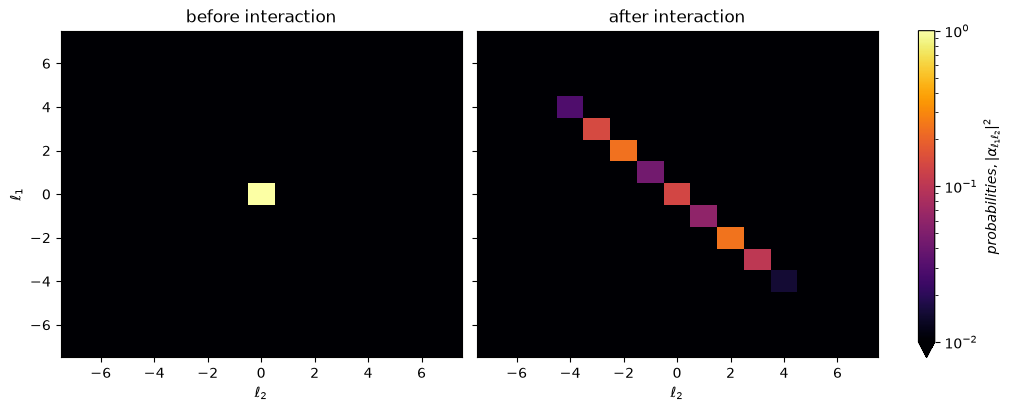

In [3]:
ls   = np.arange(-model.lmax,model.lmax+1,1)
prob_0     = ((alpha0.abs())**2).numpy()
prob_final = ((alpha.abs() )**2).numpy()


print(f'is probability conserved? -> {prob_final.sum().item():.2f} (should be ~1.0)')


prob_0     = np.where(prob_0 > 1e-5,     prob_0,    1e-5)
prob_final = np.where(prob_final > 1e-5, prob_final, 1e-5)

vmin = 1e-2
vmax = 1
fig, (ax1,ax2) = plt.subplots(1,2,sharey=True,figsize=(10,4),layout='constrained')
colormap = 'inferno'
cmsh1 = ax1.pcolormesh(ls,ls,prob_0,norm=LogNorm(vmin=vmin,vmax=vmax),cmap=colormap)
cmsh2 = ax2.pcolormesh(ls,ls,prob_final,norm=LogNorm(vmin=vmin,vmax=vmax),cmap=colormap)
fig.colorbar(cmsh2, ax = [ax1,ax2], label = r'$probabilities, |\alpha_{\ell_1 \ell_2}|^2$',extend='min')
ax1.set_ylabel(r'$\ell_1$')
ax1.set_xlabel(r'$\ell_2$')
ax2.set_xlabel(r'$\ell_2$')
ax1.set_title('before interaction')
ax2.set_title('after interaction')
plt.show()

The most significant sideband probabilities are those in the anti-diagonal $\ell_2 = -\ell_1$, which correspond to events where the electron and the lasers exchange $\ell_1$ quanta of energy $\hbar\omega_{12} = \hbar(\omega_1-\omega_2)$. As mentioned in the paper, this is a resonant process and thus it is favoured, yielding much larger probabilities than the off-resonance processes. We also see slight asymmetries related to the joint effect of the recoil effects + the Gouy phase.

Before moving on, we take a quick gradient test to check that the optimization, based on the gradient descent method, will work correctly. The test is based on a comparison between the autograd computed by PyTorch and a first order finite-difference scheme. As explained in gradient_test.py, the behaviour of the finite-difference derivatives with respect to the finite-difference step $\epsilon$ is complicated, and depends on how the parameters enter the forward pass. To this end, we introduce different steps for each of the trainable parameters, with the selection based on a sweep done for this specific choice of initial parameters.

In [4]:
from gradient_test import gradient_test
eps_range = {'log_electric': 1e-4, 'log_fr_diff': 1e-8, 'log_kinetic': 1e-8,'log_distance': 1e-6}
gradient_test(model,alpha0,eps=eps_range,doc_order=1,rtol=1e-4)

parameter           analytic       numeric     rel err
log_electric       1.031e+00     1.031e+00    5.22e-07
log_fr_diff        3.165e+03     3.166e+03    9.15e-06
log_kinetic       -1.085e+03    -1.085e+03    2.04e-05
log_distance       7.254e-03     7.254e-03    2.16e-10


{'log_electric': (1.031303403635625, 1.031302865551198, 5.217520914452184e-07),
 'log_fr_diff': (3165.4758366668366,
  3165.5047879997064,
  9.145881876277964e-06),
 'log_kinetic': (-1084.7098045371868,
  -1084.7319338369575,
  2.040070830448511e-05),
 'log_distance': (0.00725437066130726,
  0.007254370659737219,
  2.1642690257466755e-10)}

Ok! The gradients compare well with the numerical derivative, so we can move on to the optimization.

**OPTIMIZATION** 

Here, we will optimize the physical interaction parameters in order to obtain highly compressed beams. We take as a measure of compression the so-called degree of coherence 

${\rm DOC}_m = |I_m/I_0|^2$ with $ I_m = \int_{-\pi/\Omega}^{\pi/\Omega} \,{\rm e}^{m{\rm i} \Omega t}\, |\psi(z,t)|^2 dt $

where $\Omega$ is a reference frequency. The details about ${\rm DOC}_m$ can be found in the paper or in metric.py, but in short it is a quantity that compares the effect of the electron with a point-particle when interacting with a mode of frequency $m\Omega$, for a perfectly-compressed electron we get ${\rm DOC}_m = 1$, while for a very broad probability distribution we instead find ${\rm DOC}_m = 0$. 

One might wonder why we are using this complicated measure instead of just measuring the width of the peaks (using for example the full width at half max). The main difference is that the ${\rm DOC}_m$ works more like a standard deviation, in the sense that it degrades if the electron probability density has a slowly decreasing background, favouring peaks that have the highest contrast, and thus were the electron is strongly localized. 

Here, we will try to minimize a loss function defined as $L = 1-{\rm DOC}_1$, that in turn maximizes the degree of coherence (order 1). To do so, we take as our learned parameters:

1) the kinetic energy of the electron (which sets its velocity)
2) the electric field amplitude of laser 1 $(E_1)$, with the amplitude of the other laser fixed at $E_2 = E_1 (\omega_2/\omega_1)^{1/2}$ 
3) the frequency difference between the two lasers $\omega_{12} = (\omega_1-\omega_2)$ 
3) the free-propagation distance after interaction, which will tell us where the beam presents the train of pulses that are most compressed.

As explained in the paper, the ${\rm DOC}_1$ can surpass the 0.34 theoretical analytical maximum from the nonrecoil PINEM-like solution due to the recoil effects that reshape the sideband spectrum during interaction.

NOTE: the model is implemented as a differentiable PyTorch nn.Module, which is what the optimization below relies on.

We begin by showcasing the optimization algorithm with only the free-propagation distance as the learned parameter, and reuse the model from the previous example, only replacing the initial guess of the propagation distance with 0.0.

In [5]:
# we freeze the gradient of all parameters except the propagation distance 
# (the log_distance is because we actually optimize the parameters in log-scale, for more information see optimize.py)
# when setting distance = 0, the model sets distance = zT/4 instead to avoid problems when computing the log-scale parameters
m_sing = ElectronModulator(cfg,kinetic,electric1,freq_diff,0.0,use_gouy = True)
for name, p in m_sing.named_parameters(): 
    p.requires_grad_(name == 'log_distance') 

steps      = 150    # number of steps in the optimization
lr         = 1e-2   # learning rate
hist_sing  = optimize(m_sing,steps,lr,ref_freq=freq_diff)

The optimizer tracks the sideband leak, which is essentially checking that the probabilities inside the higher order sidebands ($|\ell_{1,2}| = \ell_{\rm max}$) remain small ($\ll 1$). This can be important because the discretization grid (sideband number, interaction extent and point density in the interaction) is frozen, so the optimization might actually introduce parameters for which the grid is not large enough. Here, the interaction parameters are not being optimized there should be no problem, but we print it as a sanity check.

NOTE: The optimizer actually has a warning built in that will let us know if the leak is larger than 1e-2. However, we can still print the maximum each time to see how close we are to this bound.

max sideband leak: 0.000001 (should be << 1)


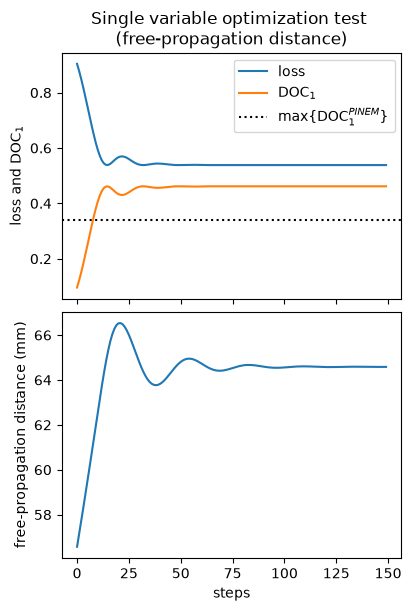

In [6]:
histarray = np.array(hist_sing)
loss_hist = histarray[:,0]
doc_hist  = histarray[:,1]
leak      = histarray[:,2]
dist_hist = histarray[:,-1]

print(f'max sideband leak: {np.max(leak):.6f} (should be << 1)')

fig,(ax1,ax2) = plt.subplots(2,1,sharex = True,figsize = (4,6),layout='constrained')

ax1.set_title('Single variable optimization test \n' + '(free-propagation distance)')

ax1.plot(loss_hist, label = 'loss')
ax1.plot(doc_hist,label = r'${\rm DOC}_1$')
ax1.axhline(0.34,color = 'k', linestyle=':',label=r'${\rm max}\{{\rm DOC}_1^{PINEM}\}$')
ax1.set_ylabel(r'loss and ${\rm DOC}_1$')
ax1.legend()

ax2.plot(dist_hist) # the optimizer returns values in the units of the inputs!
ax2.set_xlabel('steps')
ax2.set_ylabel('free-propagation distance (mm)')
plt.show()

After around 25 steps, the optimizer seems to have converged on the loss function and the ${\rm DOC}_1$, while the distance still seems to still be slightly shifting until the end. The convergence of the measure of compression is much faster than the convergence of the parameter to the final value. This can be interpreted as the temporal compression being robust against changes in the propagation distance in the order of a few millimeters.

It is interesting to note that even with our crude initial guess we are able to surpass the analytical PINEM limit due to the combination of recoil and Gouy-phase associated effects.

We now move to the more general case, where we let all four training parameters run free and try to improve the results obtained from our first guess. 

In [ ]:
from metric import degree_of_coherence

kinetic_init   = kinetic
electric_init  = electric1
freq_diff_init = freq_diff
m_full = ElectronModulator(cfg,kinetic_init,electric_init,freq_diff_init,0.0,use_gouy = True)
# we store the modulator and the energy matrix obtained from the initialization parameters to use later
with torch.no_grad():
    alpha_init = m_full(alpha0)
    m_init = ElectronModulator(cfg,kinetic_init,electric_init,freq_diff_init,0.0,use_gouy = True)
steps = 150      
lr    = 5e-3   
hist_tot  = optimize(m_full,steps,lr,ref_freq=freq_diff)

In [ ]:
histarray = np.array(hist_tot)
loss_hist = histarray[:,0]
doc_hist  = histarray[:,1]
leak      = histarray[:,2]
elec_hist = histarray[:,3]
kine_hist = histarray[:,4]
diff_hist = histarray[:,5]
dist_hist = histarray[:,6]

print(f'max sideband leak: {np.max(leak):.6f} (should be << 1)')

fig,axes = plt.subplots(5,1,sharex = True,figsize = (4,12),layout='constrained')

axes[0].set_title('Full optimization test')

axes[0].plot(loss_hist, label = 'loss')
axes[0].plot(doc_hist,label = r'${\rm DOC}_1$')
axes[0].plot([0,steps],[0.34,0.34],color = 'k', linestyle='--',label=r'${\rm max}\{{\rm DOC}_1^{PINEM}\}$')
axes[0].set_ylabel(r'loss and ${\rm DOC}_1$')
axes[0].legend()

axes[1].plot(elec_hist)
axes[1].set_ylabel('electric field amplitude (eV/nm)')

axes[2].plot(kine_hist*1e-3)
axes[2].set_ylabel('electron kinetic energy (keV)')

axes[3].plot(dist_hist)
axes[3].set_ylabel('free-propagation distance (mm)')

axes[4].plot(dist_hist)
axes[4].set_ylabel('free-propagation distance (mm)')

axes[5].plot(diff_hist)
axes[5].set_xlabel('steps')
axes[5].set_ylabel('free-propagation distance (mm)')

plt.show()

NameError: name 'np' is not defined

Now, lets do a more visual demonstration of how the optimization has improved the temporal compression. Lets look at the evolution of the electron through one period (one Talbot length) and at the optimized position of maximal compression. We'll compare the electron probability density during free-propagation in both the unoptimized initial guess and the result after optimization.

In [ ]:
from physics import interaction,free_propagation

# the initial guess has already been stored in alpha_init

def propagation_map(m, alpha0, n_beats = 5, Nz = 200, Nt = 300):
    with torch.no_grad():
        alpha = interaction(m,alpha0)
        lmax,L = m.lmax,m.L
        l = torch.arange(0, L) - lmax
        l1, l2 = l[:, None], l[None, :]
        w = l1*m.frequency1 + l2*m.frequency2
        zt, dw = m.talbot_distance, m.fr_diff

        phi = (2*np.pi/zt) * w**2 * dw**-2
        z = torch.linspace(0, zt.item(), Nz, dtype=torch.float64)
        a_z = alpha[None] * torch.exp(1j * phi[None] * z[:, None, None])

        T = (2*np.pi/dw.abs()).item()
        t = torch.linspace(0, n_beats*T, Nt, dtype=torch.float64)
        ph = torch.exp(-1j * w[None] * t[:, None, None])
        rho = torch.einsum('zij,tij->zt', a_z, ph).abs()**2  # we compute the probability density i.e. |\psi|^2
    return t.numpy()/T, z.numpy()/zt.item(), rho.numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, (m, title) in zip(axes, [(m_init, 'before'), (m_full, 'after')]):
    t, z, rho = propagation_map(m, alpha0)
    im = ax.pcolormesh(t, z, rho, shading='auto')
    ax.set_title(title); ax.set_xlabel(r'$t/T_\Omega$')
axes[0].set_ylabel(r'$z/z_T$')
fig.colorbar(im, ax=axes, label=r'$|\psi|^2$')